In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

In [2]:
build_history = pd.read_csv("build_history.csv")
build_history["site_manager_id"] = build_history["site_manager"].map({name: f"Manager_{i:03d}" for i, name in enumerate(sorted(build_history["site_manager"].dropna().unique()), 1)})
build_history["site_manager"] = build_history["site_manager_id"]

## 1. Data Exploration and Cleaning

### 1.1 Initial Data Inspection

In [3]:
build_history.shape

(4684, 31)

In [4]:
#build_history.head()
# As it is confidential

In [5]:
build_history.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4684 entries, 0 to 4683
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   home_id                  4684 non-null   object 
 1   community                4684 non-null   object 
 2   metro                    4684 non-null   object 
 3   permit_authority         4684 non-null   object 
 4   lot_number               4684 non-null   int64  
 5   plan_name                4684 non-null   object 
 6   plan_code                4684 non-null   object 
 7   product_line             4684 non-null   object 
 8   beds                     4543 non-null   float64
 9   baths                    4684 non-null   int64  
 10  half_baths               4684 non-null   int64  
 11  sqft                     4684 non-null   int64  
 12  stories                  4684 non-null   int64  
 13  garage_size              4684 non-null   object 
 14  basement_type           

##### A few note: 
##### 4,684 rows and 30 columns.
##### Several columns have missing values.
##### Date columns are currently object, so later we'll convert them to actual dates.

### 1.2 Date Conversion

In [6]:
date_cols = ["sale_date", "permit_application_date", "permit_issue_date", "construction_start_date", "construction_end_date", "final_inspection_date"]
for col in date_cols:
    build_history[col] = pd.to_datetime(build_history[col], errors="coerce")

##### Let’s check how many are Complete and how many are In Progress:

In [7]:
build_history["construction_status"].value_counts()

construction_status
Complete       4105
In Progress     579
Name: count, dtype: int64

### 1.3 Filter the data
##### We must focus only on the ones that are complete, and I call it 'completed' data

In [8]:
completed_data = build_history[build_history["construction_status"] == "Complete"].copy()

### 1.4 Drop Invalid Cycle Times

In [9]:
completed_data["cycle_days"] = (completed_data["construction_end_date"] - completed_data["construction_start_date"]).dt.days
completed_data["cycle_days"].describe()

count    4105.000000
mean      187.132521
std        63.050047
min        -8.000000
25%       140.000000
50%       178.000000
75%       224.000000
max       622.000000
Name: cycle_days, dtype: float64

In [10]:
(completed_data["cycle_days"] <= 0).sum()

7

##### We found 7 impossible records where the construction end date is before the start date. We should exclude them from the training data.

In [11]:
completed_data = completed_data[completed_data["cycle_days"] > 0].copy()
completed_data["cycle_days"].describe()

count    4098.000000
mean      187.459736
std        62.604219
min        65.000000
25%       140.000000
50%       178.000000
75%       224.000000
max       622.000000
Name: cycle_days, dtype: float64

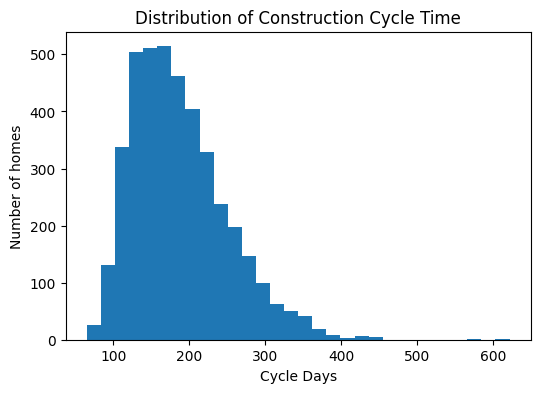

In [12]:
import matplotlib.pyplot as plt
plt.figure(figsize=(6, 4))
plt.hist(completed_data["cycle_days"], bins=30)
plt.xlabel("Cycle Days")
plt.ylabel("Number of homes")
plt.title("Distribution of Construction Cycle Time")
plt.show()

In [13]:
extreme_builds = completed_data[completed_data["cycle_days"] > 450]
display(extreme_builds)

,home_id,community,metro,permit_authority,lot_number,plan_name,plan_code,product_line,beds,baths,...,permit_issue_date,construction_start_date,construction_end_date,final_inspection_date,change_order_count,trade_invoice_total,data_source,construction_status,site_manager_id,cycle_days
1043,H100801,Auburn Meadows,Calgary,City of Calgary,280,Nyssa,SF-309,Single Family,5.0,5,...,2021-11-16,2021-12-21,2023-07-15,2023-07-12,5,1306100.0,BUILDPRO_EXPORT,Complete,Manager_015,571
4255,H101594,Auburn Meadows,Calgary,City of Calgary,125,Nyssa,SF-309,Single Family,NaN,5,...,2022-09-06,2022-10-20,2024-07-03,2024-06-30,3,1259500.0,BUILDPRO_EXPORT,Complete,Manager_012,622


##### I decided to keep them!

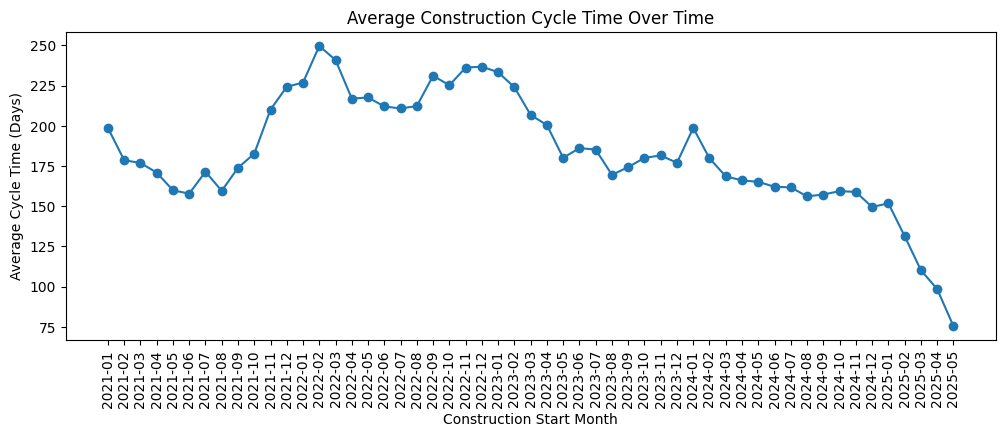

In [14]:
completed_data["start_month"] = (completed_data["construction_start_date"].dt.to_period("M"))
monthly_avg = (completed_data.groupby("start_month")["cycle_days"].mean().reset_index())
monthly_avg["start_month"] = monthly_avg["start_month"].astype(str)
plt.figure(figsize=(12, 4))
plt.plot(monthly_avg["start_month"], monthly_avg["cycle_days"], marker="o")
plt.xlabel("Construction Start Month")
plt.ylabel("Average Cycle Time (Days)")
plt.title("Average Construction Cycle Time Over Time")
plt.xticks(rotation=90)
plt.show()

### 1.5 Find Duplicates

In [15]:
completed_data.duplicated().sum()

21

In [16]:
completed_data = completed_data.drop_duplicates().copy()

### 1.6 In-Progress Filtering 

In [17]:
status_by_year = pd.crosstab(build_history["construction_start_date"].dt.year, build_history["construction_status"])
display(status_by_year)

construction_status,Complete,In Progress
construction_start_date,,
2021,829,0
2022,984,0
2023,1045,0
2024,1091,32
2025,156,547


In [18]:
months = pd.period_range("2024-01", "2025-07", freq="M")
monthly_completion = pd.DataFrame(index=months)
monthly_completion["total_builds"] = (build_history.groupby(build_history["construction_start_date"].dt.to_period("M")).size())
monthly_completion["completed_builds"] = (build_history[build_history["construction_status"] == "Complete"]
                                          .groupby(build_history["construction_start_date"].dt.to_period("M")).size())
monthly_completion = monthly_completion.fillna(0)
monthly_completion["completion_rate"] = (monthly_completion["completed_builds"] / monthly_completion["total_builds"] * 100)
monthly_completion

,total_builds,completed_builds,completion_rate
2024-01,75,75.0,100.000000
2024-02,86,86.0,100.000000
2024-03,96,96.0,100.000000
2024-04,96,96.0,100.000000
2024-05,99,99.0,100.000000
2024-06,81,81.0,100.000000
2024-07,107,107.0,100.000000
2024-08,91,90.0,98.901099
2024-09,113,112.0,99.115044
2024-10,89,89.0,100.000000


##### This shows that after October 2024, the chance of In progress is much higher. The reason is maybe longer builds need longer time.
##### So for modeling, I use the completed homes that started no later than October 31, 2024. That avoids training on artificially short recent builds.

In [19]:
model_data = completed_data[completed_data["construction_start_date"] <= "2024-10-31"].copy()
len(model_data)

3762

## 2. Feature Engineering and Selection

### 2.1 Define the important columns:

In [20]:
feature_summary = pd.DataFrame({
    "dtype": model_data.dtypes,
    "n_unique": model_data.nunique(),
    "missing": model_data.isna().sum()
}).sort_values("n_unique", ascending=False)

display(feature_summary)

,dtype,n_unique,missing
home_id,object,3762,0
trade_invoice_total,float64,2752,0
permit_application_date,datetime64[ns],1322,0
final_inspection_date,datetime64[ns],1320,0
construction_end_date,datetime64[ns],1316,0
permit_issue_date,datetime64[ns],1314,0
construction_start_date,datetime64[ns],1307,0
sale_date,datetime64[ns],1208,1266
selected_options_value,int64,748,0
lot_number,int64,419,0


#### A few things:
###### data_source has only 1 value. So, useless for prediction.
###### lot_number has 419 values and probably more like an identifier than a meaningful feature.
###### plan_name and plan_code both have exactly 16 values. I checked by observations that they are the same and later will drop plan_name.
###### Also, these columns should not be considered: "construction_end_date", "final_inspection_date", "change_order_count", "trade_invoice_total", "home_id", "construction_status", "cycle_days


### 2.2 Define Date-Based Features
- permit_processing_days.
- permit_to_start_days.
- start_year and start_month that capture time trends and seasonality.

In [21]:
model_data["permit_processing_days"] = (model_data["permit_issue_date"] - model_data["permit_application_date"]).dt.days
model_data["permit_to_start_days"] = (model_data["construction_start_date"] - model_data["permit_issue_date"]).dt.days
model_data["sale_to_start_days"] = (model_data["construction_start_date"] - model_data["sale_date"]).dt.days
model_data["sale_date_missing"] = model_data["sale_date"].isna().astype(int)
model_data["start_year"] = model_data["construction_start_date"].dt.year
model_data["start_month"] = model_data["construction_start_date"].dt.month

In [22]:
print(model_data[["sale_date", "sale_to_start_days"]].isna().sum())

sale_date             1266
sale_to_start_days    1266
dtype: int64


This isn't necessarily a problem. Some homes may be spec homes, meaning construction started before a buyer purchased them.

pd.crosstab(model_data["is_spec_home"], model_data["sale_date"].isna(), margins=True)

**is_spec_home** shows unsold at construction start. All 862 spec homes have missing sale dates, which makes sense because spec homes are unsold when construction starts.
I add a binary feature called sale_date_missing. 
Also, I add 

In [23]:
model_data["sale_date_missing"] = model_data["sale_date"].isna().astype(int)

### 2.3 Final Feature Set

In [24]:
feature_cols = ["community", "metro", "permit_authority", "plan_code", "product_line", "beds", "baths", "half_baths",
    "sqft", "stories", "garage_size", "basement_type", "lot_type", "lot_size_sqft", "is_spec_home", "selected_options_value",
    "site_manager", "permit_processing_days", "permit_to_start_days", "sale_to_start_days", "start_year", "start_month", "sale_date_missing"]

## 3. Validation Strategy and Baselines

In [25]:
# Let's check something:
print("Projects completed in 2024 or later but started before 2024:", ((model_data["construction_start_date"] < "2024-01-01") & (model_data["construction_end_date"] >= "2024-01-01")).sum())

Projects completed in 2024 or later but started before 2024: 533


This shows that in the splitting data, we should not only focus on the starting date. For example, if we split the data at begining of 2024 based on construction_start_date, then we have some construction_finish_date after 2024, which is data leakage.

In [26]:
train_data = model_data[(model_data["construction_start_date"] < "2024-01-01") & (model_data["construction_end_date"] < "2024-01-01")].copy()
val_data = model_data[model_data["construction_start_date"] >= "2024-01-01"].copy()
print("Training rows:", len(train_data))
print("Validation rows:", len(val_data))

Training rows: 2306
Validation rows: 923


### 3.1 Global Mean Baseline

In [27]:
global_mean = train_data["cycle_days"].mean()
round(global_mean, 2)

197.73

In [28]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
val_global_pred = np.full(len(val_data), global_mean) # Creates one prediction for every validation row, all equal to the training average.
global_mae = mean_absolute_error(val_data["cycle_days"], val_global_pred)
global_rmse = np.sqrt(mean_squared_error(val_data["cycle_days"], val_global_pred))

In [29]:
print("MAE:", round(global_mae, 2))
print("RMSE:", round(global_rmse, 2))

MAE: 50.26
RMSE: 59.1


### 3.2 Per-Floor-Plan Baseline

In [30]:
plan_mean = train_data.groupby("plan_code")["cycle_days"].mean()
val_plan_pred = (val_data["plan_code"].map(plan_mean).fillna(global_mean))
plan_mae = mean_absolute_error(val_data["cycle_days"], val_plan_pred)
plan_rmse = np.sqrt(mean_squared_error(val_data["cycle_days"], val_plan_pred))

print("MAE:", round(plan_mae, 2))
print("RMSE:", round(plan_rmse, 2))

MAE: 37.27
RMSE: 45.23


Per-Floor-Plan is better than Global Baseline.

## 4. Data Preprocessing

In [31]:
X_train = train_data[feature_cols].copy()
y_train = train_data["cycle_days"].copy()

X_val = val_data[feature_cols].copy()
y_val = val_data["cycle_days"].copy()

In [32]:
categorical_features = ["community", "metro", "permit_authority", "plan_code", "product_line", "garage_size", "basement_type", 
                        "lot_type", "site_manager"]

numeric_features = ["beds", "baths", "half_baths", "sqft", "stories", "lot_size_sqft", "is_spec_home", "selected_options_value",
    "permit_processing_days", "permit_to_start_days", "sale_to_start_days", "start_year", "start_month"]

### 4.1 Missing-Value Treatment

In [33]:
X_train_clean = X_train.copy()
X_val_clean = X_val.copy()

## numeric values.
for col in numeric_features:
    median_value = X_train_clean[col].median()
    X_train_clean[col] = X_train_clean[col].fillna(median_value)
    X_val_clean[col] = X_val_clean[col].fillna(median_value)

## categorical values.
for col in categorical_features:
    X_train_clean[col] = X_train_clean[col].fillna("Missing")
    X_val_clean[col] = X_val_clean[col].fillna("Missing")

### 4.2 Categorical Encoding

In [34]:
X_train_encoded = pd.get_dummies(X_train_clean, columns=categorical_features)
X_val_encoded = pd.get_dummies(X_val_clean, columns=categorical_features)
X_train_encoded.shape, X_val_encoded.shape

((2306, 142), (923, 126))

In [35]:
X_val_encoded = X_val_encoded.reindex(columns=X_train_encoded.columns, fill_value=0)
print("Validation shape:", X_val_encoded.shape)

Validation shape: (923, 142)


## 5. Model Development and Evaluation

### 5.1 Ridge Regression

In [36]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_encoded)
X_val_scaled = scaler.transform(X_val_encoded)
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train_scaled, y_train)
val_ridge_pred = ridge_model.predict(X_val_scaled)
ridge_mae = mean_absolute_error(y_val, val_ridge_pred)
ridge_rmse = mean_squared_error(y_val, val_ridge_pred) ** 0.5

print("MAE:", round(ridge_mae, 2))
print("RMSE:", round(ridge_rmse, 2))

MAE: 65.84
RMSE: 72.52


##### Worse than per floor plan! The relations are not linear probably

### 5.2 Random Forest

In [37]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1)
rf_model.fit(X_train_encoded, y_train)
val_rf_pred = rf_model.predict(X_val_encoded)

rf_mae = mean_absolute_error(y_val, val_rf_pred)
rf_rmse = mean_squared_error(y_val, val_rf_pred) ** 0.5

print("MAE:", round(rf_mae, 2))
print("RMSE:", round(rf_rmse, 2))

MAE: 30.72
RMSE: 38.36


### 5.3 Gradient Boosting

In [38]:
from sklearn.ensemble import GradientBoostingRegressor
gb_model = GradientBoostingRegressor(random_state=1)
gb_model.fit(X_train_encoded, y_train)
val_gb_pred = gb_model.predict(X_val_encoded)

gb_mae = mean_absolute_error(y_val, val_gb_pred)
gb_rmse = mean_squared_error(y_val, val_gb_pred) ** 0.5

print("MAE:", round(gb_mae, 2))
print("RMSE:", round(gb_rmse, 2))

MAE: 29.74
RMSE: 36.35


### 5.4 Model Comparison

In [39]:
results = pd.DataFrame({
    "Model": ["Global Mean", "Per-Floor-Plan Mean", "Ridge Regression", "Random Forest", "Gradient Boosting"],
    "MAE": [global_mae, plan_mae, ridge_mae, rf_mae, gb_mae],
    "RMSE": [global_rmse, plan_rmse, ridge_rmse, rf_rmse, gb_rmse]})

display(results.round(2))

,Model,MAE,RMSE
0,Global Mean,50.26,59.10
1,Per-Floor-Plan Mean,37.27,45.23
2,Ridge Regression,65.84,72.52
3,Random Forest,30.72,38.36
4,Gradient Boosting,29.74,36.35


So, we choose **Gradient Boosting**.

### 5.5 Gradient Boosting Tuning

In [40]:
gb_settings = [
    {"n_estimators": 100, "learning_rate": 0.10, "max_depth": 3},
    {"n_estimators": 200, "learning_rate": 0.05, "max_depth": 3},
    {"n_estimators": 300, "learning_rate": 0.03, "max_depth": 3},
    {"n_estimators": 150, "learning_rate": 0.05, "max_depth": 2},
    {"n_estimators": 200, "learning_rate": 0.05, "max_depth": 2},
    {"n_estimators": 200, "learning_rate": 0.05, "max_depth": 4}
]

tuning_results = []

for setting in gb_settings:
    model = GradientBoostingRegressor(
        n_estimators=setting["n_estimators"],
        learning_rate=setting["learning_rate"],
        max_depth=setting["max_depth"],
        random_state=42)
    model.fit(X_train_encoded, y_train)
    predictions = model.predict(X_val_encoded)
    mae = mean_absolute_error(y_val, predictions)
    rmse = mean_squared_error(y_val, predictions) ** 0.5
    tuning_results.append({**setting, "MAE": mae, "RMSE": rmse})
gb_tuning = pd.DataFrame(tuning_results).sort_values("MAE")
display(gb_tuning.round(2))

,n_estimators,learning_rate,max_depth,MAE,RMSE
5,200,0.05,4,28.20,34.75
1,200,0.05,3,29.21,35.74
2,300,0.03,3,29.44,35.98
0,100,0.10,3,29.75,36.36
4,200,0.05,2,31.76,38.70
3,150,0.05,2,32.60,39.48


### 5.6 Rolling Time Validation

In [41]:
def prepare_features(train_df, val_df):
    X_train = train_df[feature_cols].copy()
    X_val = val_df[feature_cols].copy()    
    for col in numeric_features:
        median_value = X_train[col].median()
        X_train[col] = X_train[col].fillna(median_value)
        X_val[col] = X_val[col].fillna(median_value)
    for col in categorical_features:
        X_train[col] = X_train[col].fillna("Missing")
        X_val[col] = X_val[col].fillna("Missing")
    X_train = pd.get_dummies(X_train, columns=categorical_features)
    X_val = pd.get_dummies(X_val, columns=categorical_features)
    X_val = X_val.reindex(columns=X_train.columns, fill_value=0)
    return X_train, X_val

time_splits = [
    ("2021 → 2022", "2022-01-01", "2022-12-31"),
    ("2021-22 → 2023", "2023-01-01", "2023-12-31"),
    ("2021-23 → 2024", "2024-01-01", "2024-10-31")
]

# Compare original and tuned Gradient Boosting configurations
configs = {
    "Original": {"n_estimators": 300, "learning_rate": 0.1, "max_depth": 3},
    "Tuned": {"n_estimators": 200, "learning_rate": 0.05, "max_depth": 4}
}

rolling_results = []

for name, val_start, val_end in time_splits:
    train_fold = model_data[(model_data["construction_start_date"] < val_start) & (model_data["construction_end_date"] < val_start)].copy()
    val_fold = model_data[(model_data["construction_start_date"] >= val_start) & (model_data["construction_start_date"] <= val_end)].copy()

    X_train_fold, X_val_fold = prepare_features(train_fold, val_fold)
    row = {"Split": name, "Train rows": len(train_fold), "Validation rows": len(val_fold)}

    for label, params in configs.items():
        model = GradientBoostingRegressor(**params, random_state=42)
        model.fit(X_train_fold, train_fold["cycle_days"])
        predictions = model.predict(X_val_fold)

        row[f"{label} MAE"] = mean_absolute_error(val_fold["cycle_days"], predictions)
        row[f"{label} RMSE"] = mean_squared_error(val_fold["cycle_days"], predictions) ** 0.5

    rolling_results.append(row)

rolling_results = pd.DataFrame(rolling_results)
display(rolling_results.round(2))

,Split,Train rows,Validation rows,Original MAE,Original RMSE,Tuned MAE,Tuned RMSE
0,2021 → 2022,426,978,76.58,92.44,76.99,92.89
1,2021-22 → 2023,1176,1039,28.72,37.08,28.38,37.15
2,2021-23 → 2024,2306,923,29.39,36.34,28.20,34.75


Not completely satisfied.


### 5.7 Nested Rolling Time Validation

In [42]:

# Outer validation year, inner validation start, outer validation start/end
nested_splits = [
    ("2023", "2022-01-01", "2023-01-01", "2024-01-01"),
    ("2024", "2023-01-01", "2024-01-01", "2024-11-01")]

nested_results = []

for year, inner_start, outer_start, outer_end in nested_splits:

    # 1. Inner training: projects completed before inner validation
    inner_train = model_data[(model_data["construction_start_date"] < inner_start) & (model_data["construction_end_date"] < inner_start)].copy()

    # 2. Inner validation: projects whose outcomes were known before outer validation
    inner_val = model_data[(model_data["construction_start_date"] >= inner_start) & (model_data["construction_start_date"] < outer_start) & (model_data["construction_end_date"] < outer_start)].copy()

    X_inner_train, X_inner_val = prepare_features(inner_train, inner_val)

    # 3. Tune the six Gradient Boosting configurations
    tuning_results = []

    for params in gb_settings:
        model = GradientBoostingRegressor(**params, random_state=42)
        model.fit(X_inner_train, inner_train["cycle_days"])
        predictions = model.predict(X_inner_val)

        tuning_results.append({**params, "MAE": mean_absolute_error(inner_val["cycle_days"], predictions)})

    best_params = min(tuning_results, key=lambda x: x["MAE"])
    selected_params = {k: best_params[k] for k in ["n_estimators", "learning_rate", "max_depth"]}

    # 4. Outer training: all completed projects available before the outer year
    outer_train = model_data[(model_data["construction_start_date"] < outer_start) & (model_data["construction_end_date"] < outer_start)].copy()

    # 5. Outer validation: projects starting during the evaluation year
    outer_val = model_data[(model_data["construction_start_date"] >= outer_start) & (model_data["construction_start_date"] < outer_end)].copy()

    X_outer_train, X_outer_val = prepare_features(outer_train, outer_val)

    # 6. Refit selected model on all eligible outer training data
    final_model = GradientBoostingRegressor(**selected_params, random_state=42)
    final_model.fit(X_outer_train, outer_train["cycle_days"])
    predictions = final_model.predict(X_outer_val)

    plan_mean = outer_train.groupby("plan_code")["cycle_days"].mean()
    baseline_pred = outer_val["plan_code"].map(plan_mean).fillna(outer_train["cycle_days"].mean())

    # 7. Save independent outer-fold evaluation metrics
    nested_results.append({
        "Year": year,
        "Inner train": len(inner_train),
        "Inner val": len(inner_val),
        "Outer train": len(outer_train),
        "Outer val": len(outer_val),
        **selected_params,
        "Inner MAE": best_params["MAE"],
        "Outer MAE": mean_absolute_error(outer_val["cycle_days"], predictions),
        "Outer RMSE": mean_squared_error(outer_val["cycle_days"], predictions) ** 0.5,
        "Baseline MAE": mean_absolute_error(outer_val["cycle_days"], baseline_pred),
        "Baseline RMSE": mean_squared_error(outer_val["cycle_days"], baseline_pred) ** 0.5
    })

nested_results = pd.DataFrame(nested_results)
nested_results["MAE Improvement (%)"] = 100 * (nested_results["Baseline MAE"] - nested_results["Outer MAE"]) / nested_results["Baseline MAE"]
display(nested_results.round(1))


,Year,Inner train,Inner val,Outer train,Outer val,n_estimators,learning_rate,max_depth,Inner MAE,Outer MAE,Outer RMSE,Baseline MAE,Baseline RMSE,MAE Improvement (%)
0,2023,426,357,1176,1039,100,0.1,3,41.1,28.3,36.8,35.4,47.3,20.2
1,2024,1176,514,2306,923,200,0.0,3,24.7,29.2,35.7,37.3,45.2,21.6


## 6. Model Interpretation

### 6.1 Individual Feature Importance

In [43]:
feature_importance = pd.DataFrame({
    "feature": X_train_encoded.columns,
    "importance": gb_model.feature_importances_ })

feature_importance = feature_importance.sort_values("importance", ascending=False)
display(feature_importance.head(15))

,feature,importance
3,sqft,0.481247
11,start_year,0.169723
12,start_month,0.079102
7,selected_options_value,0.066217
6,is_spec_home,0.048421
118,basement_type_Finished,0.025840
85,metro_Edmonton,0.012091
5,lot_size_sqft,0.011364
123,lot_type_Walkout,0.010682
119,basement_type_Missing,0.008582


### 6.2 Grouped Feature Importance

In [44]:
group_importance = {}

for feature, importance in zip(X_train_encoded.columns, gb_model.feature_importances_):
    original_feature = feature
    for col in categorical_features:
        if feature.startswith(col + "_"):
            original_feature = col
            break
    group_importance[original_feature] = (group_importance.get(original_feature, 0) + importance)

group_importance = (pd.DataFrame(group_importance.items(), columns=["Feature", "Importance"]).sort_values("Importance", ascending=False))

display(group_importance)

,Feature,Importance
3,sqft,0.481247
11,start_year,0.169723
12,start_month,0.079102
7,selected_options_value,0.066217
6,is_spec_home,0.048421
20,basement_type,0.034423
14,community,0.033987
22,site_manager,0.018489
15,metro,0.012965
5,lot_size_sqft,0.011364


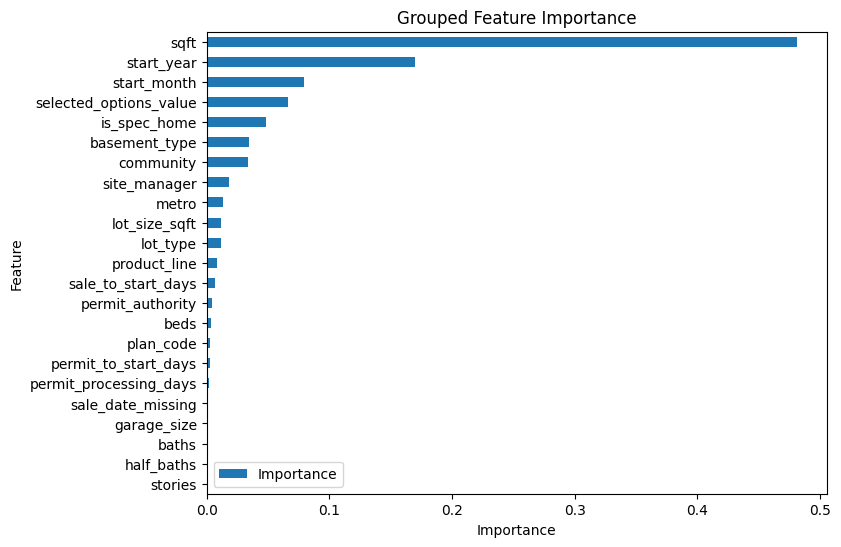

In [45]:
group_importance.plot(x="Feature", y="Importance", kind="barh", figsize=(8, 6))
plt.gca().invert_yaxis()
plt.xlabel("Importance")
plt.title("Grouped Feature Importance")
plt.show()

##### sqft is the strongest driver by far.
##### start_year and start_month confirm that time trend/seasonality matters.

### 6.2 Site Manager Analysis

#### 6.2.1 Raw Cycle-Time Comparison

In [46]:
manager_summary = model_data.groupby("site_manager")["cycle_days"].agg(count="count", mean="mean").sort_values("mean")
#display(manager_summary.round(1))

#### 6.2.2 Floor-Plan-Adjusted

In [47]:
plan_mean = model_data.groupby("plan_code")["cycle_days"].mean()
model_data["expected_plan_days"] = model_data["plan_code"].map(plan_mean)
model_data["days_vs_plan"] = (model_data["cycle_days"] - model_data["expected_plan_days"])
manager_adjusted = model_data.groupby("site_manager")["days_vs_plan"].agg(count="count",mean="mean").sort_values("mean")

display(manager_adjusted.round(1))

,count,mean
site_manager,,
Manager_016,224,-10.9
Manager_018,234,-9.0
Manager_014,230,-8.5
Manager_013,197,-7.2
Manager_015,239,-6.4
Manager_008,185,-4.8
Manager_005,213,-1.7
Manager_010,201,-1.7
Manager_011,213,-0.9
